# Two cameras at two heights: what the second one adds, and how many frames it takes

The NEOARM has the screen camera and, further down, the Merlin. A beam seen on both gives two positions along one
straight line, so it gives the direction the beam travels after the last lens, not only where it lands. This notebook
works out, on the virtual NEOARM and before anything is recorded, what that is worth:

1. at the normal magnification rows and camera lengths the second camera adds almost nothing;
2. with the lenses weak it adds the slopes, and one number that must not change;
3. an experiment built on that (one lens at a time, the others weak) finds where the lenses are, in metres;
4. how many settings that takes, and what one camera alone would give;
5. which rulers turn it into real units;
6. shift and tilt offsets: which line is the axis, and where the lens centres are;
7. why many magnifications and camera lengths alone are not enough (section 9);
8. the smallest recording that still works: about 170 frames, the Merlin at three settings only (section 10).

Everything here is TemGym only (`ElectromagneticLens` for the objective, IL1, IL2, IL3, PL1), with no PyJEM and no
images: a kick is taken straight from the column's matrix, with the noise a measured displacement has.

**The second camera here is a placeholder**: 0.45 m below the screen camera, 55 um pixels, turned by 0.3 rad, its
middle 0.7 mm off. The fit is never told any of that.

It uses a GPU if JAX has one (about ten minutes). On a CPU set `SEEDS=1` and expect much longer.

In [1]:
import json, os, time
from pathlib import Path

import jax
import jax.numpy as jnp
import numpy as np
from jax.flatten_util import ravel_pytree
from scipy.optimize import least_squares

jax.config.update("jax_enable_x64", True)
from temgym_core.components import ElectromagneticLens, Plane, Scanner
from temgym_core.constants import energy2wavelength
from temgym_core.plotting import trace_ray_paths
from temgym_core.ray import Ray
from temgym_core.run import column_matrix

TRUTH = json.loads(Path("../virtual_neoarm/virtual_neoarm.json").read_text())
LENSES = ["IL1", "IL2", "IL3", "PL1"]
VOLTAGE = 200e3
V_STAR = VOLTAGE * (1 + VOLTAGE / (2 * 510998.95))

# the two cameras of the virtual microscope: the screen camera of the file, and a placeholder Merlin below it
CAMERAS = ["screen camera", "Merlin"]
Z_CAMERA, SEPARATION = TRUTH["camera_z_m"], 0.45
PIXEL = np.array([110e-6, 55e-6])
FRAME_PX = np.array([479, 256])
ROTATION = np.array([TRUTH["camera_rotation_rad"], TRUTH["camera_rotation_rad"] + 0.3])
MERLIN_MIDDLE = complex(0.6e-3, -0.4e-3)             # where the Merlin's middle pixel is, seen from the screen camera's
KICK = np.array(TRUTH["deflectors"]["kick_per_dac"])  # CLA1 x, y and CLA2 x, y units -> x, y (m), tilt x, y (rad)
TABLE = {mode: {float(label): [dac[n] for n in LENSES] for label, dac in TRUTH["lens_table"][mode].items()}
         for mode in ("MAG", "DIFF")}
Z_TRUE = np.array([TRUTH["lenses"]["objective"]["z_m"], *[TRUTH["lenses"][n]["z_m"] for n in LENSES], Z_CAMERA])
WEAK = 3000                                          # a lens "off": 2.4 m focal length for IL1-IL3, 0.9 m for PL1


def row(mode, label, **change):
    "The lens values of a magnification row or camera length, with some lenses changed."
    dac = list(TABLE[mode][label])
    for name, value in change.items():
        dac[LENSES.index(name)] = value
    return dac


def weak(**change):
    "Every projection lens weak, except those given."
    return [change.get(name, WEAK) for name in LENSES]


print(jax.devices())

[CudaDevice(id=0)]


## 1. The virtual column, and what a kick does on each camera

A ray that leaves the specimen at position x with angle theta reaches the screen camera at A x + B theta, travelling
with slope C x + D theta. The Merlin is a straight flight further on, so there the ray is at
(A + s C) x + (B + s D) theta, with s the distance between the cameras. One camera gives A and B. Two give C and D
as well, in units of s.

A CLA1 kick changes x and a CLA2 kick changes theta, so the four responses below (shift and tilt, on each camera,
in pixels per DAC unit) are those four numbers, each times the size of a deflector unit.

In [2]:
def truth_column(dac, off_centre=True):
    "The virtual NEOARM from the specimen to the screen camera, as TemGym components."
    objective = TRUTH["lenses"]["objective"]
    parts = [ElectromagneticLens(z=objective["z_m"], turns=objective["ampere_turns"], current=1.0, Gc=objective["Gc"])]
    for i, name in enumerate(LENSES):
        lens = TRUTH["lenses"][name]
        body = ElectromagneticLens(z=lens["z_m"], turns=lens["ampere_turns_per_dac"], current=dac[i], Gc=lens["Gc"], Tc=lens["Tc"])
        if off_centre:                               # the lens acts about its own centre
            x, y = lens["offset_m"]
            parts += [Scanner(z=lens["z_m"], scan_pos_x=-x, scan_pos_y=-y), body,
                      Scanner(z=lens["z_m"] + body.thickness, scan_pos_x=x, scan_pos_y=y)]
        else:
            parts.append(body)
    return [*parts, Plane(z=Z_CAMERA)]


truth_matrices = jax.jit(jax.vmap(lambda dac: column_matrix(truth_column(dac), voltage=VOLTAGE)))


def responses(matrices):
    "px per DAC unit (x + iy) for [setting, camera, (CLA1 x, CLA1 y, CLA2 x, CLA2 y)]."
    matrices, out = np.asarray(matrices), []
    for camera, flight in enumerate((0.0, SEPARATION)):
        landed = (matrices[:, :2, :4] + flight * matrices[:, 2:4, :4]) @ KICK
        out.append(np.exp(1j * ROTATION[camera]) / PIXEL[camera] * (landed[:, 0] + 1j * landed[:, 1]))
    return np.stack(out, axis=1)


def compare_cameras(settings):
    seen = responses(truth_matrices(jnp.array([dac for _, dac in settings], float)))
    print(f"{'setting':26s} {'screen camera, px per unit':>28s}   {'Merlin image / screen image':>28s}   fixed number")
    print(f"{'':26s} {'shift':>13s} {'tilt':>14s}   {'shift':>13s} {'tilt':>14s}")
    for (name, _), r in zip(settings, seen):
        ratio = np.abs(r[1] / r[0]) * PIXEL[1] / PIXEL[0]
        ratios = [f"{ratio[i]:13.4f}" if abs(r[0, i]) * 12000 > 1 else f"{'(too small)':>13s}" for i in (0, 2)]
        fixed = abs(r[0, 0] * r[1, 2] - r[0, 2] * r[1, 0])
        print(f"{name:26s} {abs(r[0, 0]):13.2e} {abs(r[0, 2]):14.2e}   {ratios[0]} {ratios[1]}    {fixed:.4e}")

## 2. At the normal rows, the Merlin sees the same picture, only bigger

PL1 is strong (2 mm focal length), so every ray leaves it through one point just below it, and both cameras see a
projection from that point. The Merlin's picture is the screen camera's times a fixed ratio, the same for shift and
tilt, at every row and every lens step. (Where a response is under 1 px for the largest kick, its ratio is not
measurable and is left out.)

So at normal settings the second camera adds one number in total: where that point is.

In [3]:
normal = [(f"MAG {m}", row("MAG", m)) for m in (8000, 40000, 200000)]
normal += [(f"DIFF {c} m", row("DIFF", c)) for c in (0.15, 0.4, 1.0)]
normal += [(f"MAG 40000, {n} {step:+d}", row("MAG", 40000, **{n: row("MAG", 40000)[LENSES.index(n)] + step}))
           for n in LENSES for step in (-1000, 1000)]
compare_cameras(normal)

setting                      screen camera, px per unit    Merlin image / screen image   fixed number
                                   shift           tilt           shift           tilt
MAG 8000                        2.37e-02       6.10e-07          2.1976   (too small)    3.7746e-07
MAG 40000                       1.18e-01       2.30e-06          2.1965   (too small)    3.7746e-07
MAG 200000                      5.91e-01       7.66e-06          2.1963   (too small)    3.7746e-07
DIFF 0.15 m                     6.10e-06       2.13e-02     (too small)        2.1963    3.7746e-07
DIFF 0.4 m                      6.07e-07       5.67e-02     (too small)        2.1964    3.7746e-07
DIFF 1.0 m                      1.10e-05       1.42e-01     (too small)        2.1964    3.7746e-07
MAG 40000, IL1 -1000            9.55e-02       1.36e-02          2.1965        2.1964    3.7746e-07
MAG 40000, IL1 +1000            1.42e-01       1.39e-02          2.1965        2.1966    3.7746e-07
MAG 40000, 

## 3. With the last lens weak the slopes show, and one number never changes

Turn PL1 down and the rays no longer leave through one point: a shifted ray and a tilted ray cross the axis at
different heights, so shift and tilt are magnified by different ratios between the cameras. That difference is the
slope information.

**The fixed number.** `shift_1 x tilt_2 - tilt_1 x shift_2` (the four responses, cameras 1 and 2) has the same size
at every lens setting. It equals s x (one CLA1 unit) x (one CLA2 unit) / (the two pixel sizes), and needs no model
of the lenses. It is a check on every setting, and it ties the three unknown sizes together. At the normal rows it
is the small difference of two large numbers and cannot be measured; with weak lenses it can.

In [4]:
compare_cameras([(f"MAG 40000, PL1 = {v}", row("MAG", 40000, PL1=v)) for v in (64000, 48000, 32000, 20000, 12000, 6000)]
                + [("all four weak", weak())] + [(f"{n} = 32000, rest weak", weak(**{n: 32000})) for n in LENSES])
print(f"\nexpected: {SEPARATION * abs(KICK[0, 0] * KICK[2, 2]) / (PIXEL[0] * PIXEL[1]):.4e}")

setting                      screen camera, px per unit    Merlin image / screen image   fixed number
                                   shift           tilt           shift           tilt
MAG 40000, PL1 = 64000          1.18e-01       2.30e-06          2.1965   (too small)    3.7746e-07
MAG 40000, PL1 = 48000          1.28e-01       7.22e-05          2.2043   (too small)    3.7746e-07
MAG 40000, PL1 = 32000          6.69e-02       9.31e-05          2.2188        2.1885    3.7746e-07
MAG 40000, PL1 = 20000          2.24e-02       9.42e-05          2.2785        2.1891    3.7746e-07
MAG 40000, PL1 = 12000          2.41e-03       9.26e-05          3.0347        2.1892    3.7746e-07
MAG 40000, PL1 = 6000           6.19e-03       9.13e-05          1.8551        2.1892    3.7746e-07
all four weak                   7.67e-04       1.36e-03          1.3000        1.4813    3.7746e-07
IL1 = 32000, rest weak          4.43e-03       1.72e-03          1.6192        1.6440    3.7746e-07
IL2 = 32000

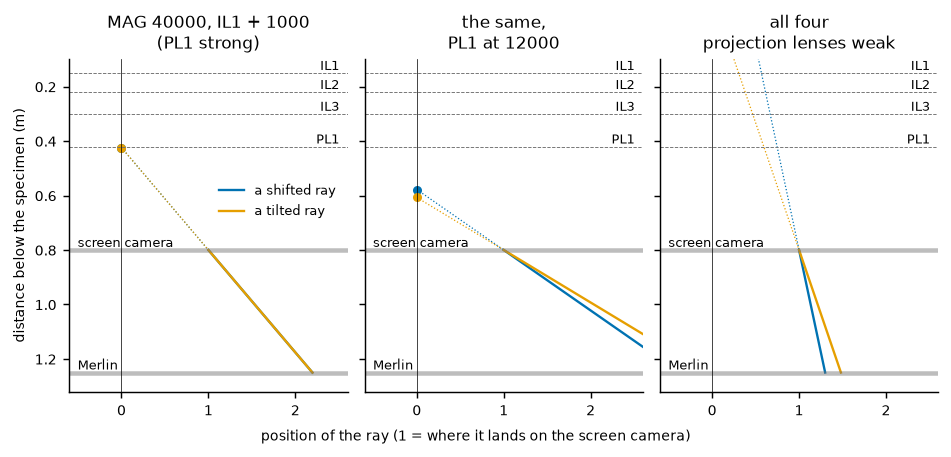

In [5]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6E6E6E"


def two_rays(dac):
    "A shifted ray and a tilted ray through the column and on to the Merlin (TemGym's traced paths, rotation undone)."
    parts = [*truth_column(jnp.array(dac, float), off_centre=False)[:-1], Plane(z=Z_CAMERA), Plane(z=Z_CAMERA + SEPARATION)]
    rays = Ray(x=jnp.array([1e-9, 0.0]), y=jnp.zeros(2), dx=jnp.array([0.0, 1e-6]), dy=jnp.zeros(2), z=jnp.zeros(2),
               pathlength=jnp.zeros(2), voltage=VOLTAGE)
    z, x = trace_ray_paths(parts, rays, ray_coordinate="x_rot")
    return np.asarray(z), np.asarray(x)


figure, panels = plt.subplots(1, 3, figsize=(7.2, 3.4), constrained_layout=True, sharey=True)
pictures = [("MAG 40000, IL1 + 1000\n(PL1 strong)", row("MAG", 40000, IL1=row("MAG", 40000)[0] + 1000)),
            ("the same,\nPL1 at 12000", row("MAG", 40000, IL1=row("MAG", 40000)[0] + 1000, PL1=12000)),
            ("all four\nprojection lenses weak", weak())]
for panel, (title, dac) in zip(panels, pictures):
    z, x = two_rays(dac)
    below = z >= TRUTH["lenses"]["PL1"]["z_m"] + 0.006
    for ray, (colour, name) in enumerate([(BLUE, "a shifted ray"), (ORANGE, "a tilted ray")]):
        on_screen = x[np.flatnonzero(z == Z_CAMERA)[0], ray]
        slope = (x[-1, ray] / on_screen - 1.0) / SEPARATION
        crossing = Z_CAMERA - 1.0 / slope
        panel.plot(x[below, ray] / on_screen, z[below], color=colour, lw=1.3, label=name)
        panel.plot([0, 1], [crossing, Z_CAMERA], color=colour, lw=0.7, ls=":")
        panel.plot(0, crossing, "o", color=colour, ms=4)
    for height, name in ((Z_CAMERA, "screen camera"), (Z_CAMERA + SEPARATION, "Merlin")):
        panel.axhline(height, color=GREY, lw=2.5, alpha=0.45)
        panel.annotate(name, (0.03, height), xycoords=("axes fraction", "data"), va="bottom", fontsize=7)
    for name in LENSES:
        panel.axhline(TRUTH["lenses"][name]["z_m"], color=GREY, lw=0.5, ls="--")
        panel.annotate(name, (0.97, TRUTH["lenses"][name]["z_m"]), xycoords=("axes fraction", "data"), ha="right", va="bottom", fontsize=7)
    panel.axvline(0, color="black", lw=0.4)
    panel.set(title=title, xlim=(-0.6, 2.6), ylim=(1.32, 0.1))
panels[0].set_ylabel("distance below the specimen (m)")
panels[0].legend(frameon=False, fontsize=7, loc="upper right", bbox_to_anchor=(1.0, 0.66))
figure.supxlabel("position of the ray (1 = where it lands on the screen camera)", fontsize=8)
plt.show()

**Figure 1, the rays after the last lens.** Each ray is drawn from PL1 down, scaled so that it lands at 1 on the
screen camera; the dotted line carries it back up to where it crosses the axis (the dot). Left: with PL1 strong both
rays come from the same point just below PL1, so the Merlin can only see a larger copy. Middle and right: with weak
lenses the two rays come from different heights (in the right panel, from above the top of the picture). Two cameras
see those heights; one camera cannot. A single strong
lens, whichever it is, behaves like the left panel, so it is the weak and middling values that carry the slopes.

## 4. The experiment: one lens at a time, the others weak

The weak settings are also the easy ones to fit: with one lens on, its place and strength are the only new unknowns.
So the recording goes up a ladder.

| Stage | Lens values | What it gives |
|---|---|---|
| all weak | every projection lens at 3000 | the objective, and the length to the cameras |
| IL1, IL2, IL3, PL1 | that lens at a few values, the other three at 3000 | where that lens is and how strong |
| rows | a few normal magnification rows and camera lengths | the lenses working together, as they are used |
| rulers | gold rings (camera lengths), a grating image (magnifications) | real radians and real metres |
| kept back | other normal rows | never fitted: the model has to predict them |

At each setting, on each camera: CLA1 and CLA2, each + and - along x and along y (4 frames per deflector), sized to
move the beam about 60 px on the screen camera and 80 px on the Merlin, or the largest kick if that is not enough:
12000 units for CLA1, and 1500 for CLA2, because a larger tilt would bring in the objective's aberrations, which
this model does not have. A displacement repeats to 0.02 px (the scatter measured in `fit_predictor.ipynb`); a ring radius or a grating
period is taken as good to 0.1 px.

In [6]:
SCATTER_PX, RULER_SCATTER_PX = 0.02, 0.1
LARGEST_KICK, AIM_PX = np.array([12000, 1500]), np.array([60.0, 80.0])       # CLA1, CLA2
RING_ANGLE = float(energy2wavelength(VOLTAGE)) / (0.40782e-9 / np.sqrt(3))     # the gold 111 ring: wavelength / spacing
PITCH = 1e-3 / 2160                                                              # a 2160 lines per mm cross-grating

SWEEP = dict(IL1=(12000, 22000, 32000, 42000), IL2=(12000, 22000, 32000, 42000), IL3=(12000, 22000, 32000, 42000),
             PL1=(12000, 24000, 40000, 64000))
ROWS = [("MAG", 40000), ("DIFF", 0.4), ("MAG", 8000), ("DIFF", 0.15), ("MAG", 200000), ("DIFF", 1.0)]
settings = [("weak", "all weak", weak())]                                        # (stage, name, lens values)
settings += [(name, f"{name} {value}", weak(**{name: value})) for name in LENSES for value in SWEEP[name]]
settings += [("rows", f"{mode} {label}", row(mode, label)) for mode, label in ROWS]
settings += [("kept", f"MAG {m}", row("MAG", m)) for m in (12000, 20000, 100000, 300000)]
settings += [("kept", f"DIFF {c}", row("DIFF", c)) for c in (0.25, 0.6, 0.8, 1.5)]
# rulers: (what, camera, lens values). Rings must fit on the camera, so the Merlin takes the short camera lengths.
rulers = [("gold", 0, row("DIFF", 0.4)), ("gold", 0, row("DIFF", 0.8)), ("gold", 1, row("DIFF", 0.15)),
          ("gold", 1, row("DIFF", 0.2)), ("grating", 0, row("MAG", 8000)), ("grating", 0, row("MAG", 12000))]
NAMES = [name for _, name, _ in settings]
DACS = np.array([dac for *_, dac in settings] + [dac for *_, dac in rulers], float)
TRUE_MATRICES = np.asarray(truth_matrices(jnp.array(DACS)))
TRUE_RESPONSES = responses(TRUE_MATRICES)

# one "kick" = one setting, one camera, one deflector: four frames
KICKS = dict(setting=[], camera=[], is_tilt=[], kick=[], stage=[])
for i, (stage, _, _) in enumerate(settings):
    for camera in (0, 1):
        for tilt in (0, 1):
            largest = np.abs(TRUE_RESPONSES[i, camera, 2 * tilt:2 * tilt + 2]).max()
            KICKS["setting"].append(i), KICKS["camera"].append(camera), KICKS["is_tilt"].append(bool(tilt))
            KICKS["kick"].append(min(LARGEST_KICK[tilt], AIM_PX[camera] / largest)), KICKS["stage"].append(stage)
KICKS = {key: np.array(value) for key, value in KICKS.items()}
RULERS = dict(setting=np.arange(len(settings), len(DACS)), camera=np.array([camera for _, camera, _ in rulers]),
              is_gold=np.array([what == "gold" for what, *_ in rulers]))


def record(rng):
    "One simulated recording: the responses and the ruler sizes, with their noise."
    which = KICKS["setting"], KICKS["camera"], 2 * KICKS["is_tilt"]
    noise = (rng.normal(0, SCATTER_PX, (2, len(KICKS["kick"]))) + 1j * rng.normal(0, SCATTER_PX, (2, len(KICKS["kick"])))) / KICKS["kick"]
    along_x = TRUE_RESPONSES[which[0], which[1], which[2]] + noise[0]
    along_y = TRUE_RESPONSES[which[0], which[1], which[2] + 1] + noise[1]
    sizes = []
    for setting, camera, is_gold in zip(RULERS["setting"], RULERS["camera"], RULERS["is_gold"]):
        m = TRUE_MATRICES[setting]
        landed = m[:2, :4] + (SEPARATION if camera else 0.0) * m[2:4, :4]
        size = abs(complex(landed[0, 2], landed[1, 2])) * RING_ANGLE if is_gold else abs(complex(landed[0, 0], landed[1, 0])) * PITCH
        sizes.append(size / PIXEL[camera] + rng.normal(0, RULER_SCATTER_PX))
    return dict(along_x=along_x, along_y=along_y, sizes=np.array(sizes))


example = record(np.random.default_rng(1))
print(f"{'setting':14s} {'lens values':30s} beam moved on the screen camera (px): CLA1, CLA2   on the Merlin: CLA1, CLA2")
for i, (stage, name, dac) in enumerate(settings):
    if stage == "kept":
        continue
    moved = [np.abs(example["along_x"][j]) * KICKS["kick"][j] for j in np.flatnonzero(KICKS["setting"] == i)]
    print(f"{name:14s} {str(dac):30s} {moved[0]:25.1f} {moved[1]:6.1f} {moved[2]:22.1f} {moved[3]:6.1f}")
print("\nrulers (px):", ", ".join(f"{what} on the {CAMERAS[camera]} {size:.1f}" for (what, camera, _), size in zip(rulers, example["sizes"])))

setting        lens values                    beam moved on the screen camera (px): CLA1, CLA2   on the Merlin: CLA1, CLA2
all weak       [3000, 3000, 3000, 3000]                             9.2    2.0                   23.9    6.0
IL1 12000      [12000, 3000, 3000, 3000]                            0.7    1.4                    2.8    4.1
IL1 22000      [22000, 3000, 3000, 3000]                           20.6    0.2                   69.6    0.8
IL1 32000      [32000, 3000, 3000, 3000]                           53.2    2.6                   80.0    8.5
IL1 42000      [42000, 3000, 3000, 3000]                           60.0    5.7                   80.0   18.3
IL2 12000      [3000, 12000, 3000, 3000]                            2.8    0.6                   16.9    1.1
IL2 22000      [3000, 22000, 3000, 3000]                           32.7    3.1                   80.0   11.3
IL2 32000      [3000, 32000, 3000, 3000]                           60.0    8.7                   80.0   30.5
IL2 4

## 5. The model, and the fit in stages

The same TemGym column as `fit_predictor.ipynb` (`ElectromagneticLens` for the objective and IL1, IL2, IL3, PL1,
with every gap between them a number to fit), and now its slopes too. New numbers: the distance between the cameras
and how far the Merlin is turned.

**The fit goes up the ladder.** Stage by stage it adds one lens's settings and frees that lens's numbers, starting
from many random places for the new lens only. During the ladder the camera distance and the CLA1 unit are held at
guesses (0.3 m and 3e-10 m, both wrong): the kicks alone cannot tell them, they only stretch the model. The last
stage adds the rows and the rulers and frees everything.

**Held at the end: nothing.**

In [7]:
def column(numbers, dac):
    "TemGym components from the specimen to the screen camera, for IL1, IL2, IL3, PL1 at these DAC values."
    z = jnp.cumsum(jnp.exp(numbers["log_gaps"]))        # objective, IL1, IL2, IL3, PL1, screen camera
    objective = ElectromagneticLens(z=z[0], turns=1.0, current=1.0, Gc=jnp.exp(numbers["log_objective_Gc"]))
    lenses = [ElectromagneticLens(z=z[i + 1], turns=numbers["ampere_turns_per_unit"][i], current=dac[i],
                                  Gc=jnp.exp(numbers["log_Gc"][i]), Tc=jnp.exp(numbers["log_Tc"][i])) for i in range(4)]
    return [objective, *lenses, Plane(z=z[5])]


def a_b_c_d(numbers, dac):
    "Position (A, B) and slope (C, D) at the screen camera per unit position and angle at the specimen (complex)."
    m = column_matrix(column(numbers, dac), voltage=VOLTAGE)
    return m[0, 0] + 1j * m[1, 0], m[0, 2] + 1j * m[1, 2], m[2, 0] + 1j * m[3, 0], m[2, 2] + 1j * m[3, 2]


def axes(deflector):
    "A deflector's x and y axes at the specimen (complex), per DAC unit."
    x_axis = jnp.exp(deflector["log_size"] + 1j * deflector["x_angle"])
    return x_axis, x_axis * (deflector["y_axis"][0] + 1j * deflector["y_axis"][1])


def on_camera(numbers, setting, camera):
    "A and B at a camera, in pixels and in the camera's own orientation, for each (setting, camera) asked for."
    a, b, c, d = jax.vmap(a_b_c_d, in_axes=(None, 0))(numbers["lenses"], jnp.asarray(DACS))
    flight = jnp.where(camera == 1, jnp.exp(numbers["log_separation"]), 0.0)
    turned = jnp.exp(1j * (numbers["camera_rotation"] + jnp.where(camera == 1, numbers["merlin_rotation"], 0.0)))
    scale = turned / jnp.asarray(PIXEL)[camera]
    return scale * (a[setting] + flight * c[setting]), scale * (b[setting] + flight * d[setting])


def predicted(numbers):
    "px per DAC unit along x and y for every kick, and the ruler sizes in px."
    a, b = on_camera(numbers, KICKS["setting"], KICKS["camera"])
    (shift_x, shift_y), (tilt_x, tilt_y) = axes(numbers["CLA1"]), axes(numbers["CLA2"])
    along_x = jnp.where(KICKS["is_tilt"], b * tilt_x, a * shift_x)
    along_y = jnp.where(KICKS["is_tilt"], b * tilt_y, a * shift_y)
    a, b = on_camera(numbers, RULERS["setting"], RULERS["camera"])
    return along_x, along_y, jnp.where(RULERS["is_gold"], jnp.abs(b) * RING_ANGLE, jnp.abs(a) * PITCH)


def guess(rng):
    "Numbers to start from: nominal lens strengths, guessed gaps, and guesses for what the kicks cannot tell."
    per_unit = np.array([-0.08, -0.08, -0.08, 0.08]) * (1 + rng.normal(0, 0.02, 4))
    ampere_turns = np.abs(per_unit) * 32768
    return dict(lenses=dict(ampere_turns_per_unit=per_unit, log_gaps=np.log([0.002, 0.1, 0.1, 0.1, 0.1, 0.4]),
                            log_objective_Gc=np.log(V_STAR / 0.002), log_Gc=np.log(V_STAR / (0.02 * ampere_turns ** 2)),
                            log_Tc=np.log(0.003 / ampere_turns)),
                camera_rotation=0.0, merlin_rotation=0.0, log_separation=np.log(0.3),
                CLA1=dict(log_size=np.log(3e-10), x_angle=0.0, y_axis=np.array([0.0, -1.0])),
                CLA2=dict(log_size=np.log(1e-5), x_angle=0.0, y_axis=np.array([0.0, -1.0])))


START = guess(np.random.default_rng(0))
_, as_numbers = ravel_pytree(START)
copy = lambda numbers: jax.tree_util.tree_map(lambda v: np.array(v, float), numbers)


def misfits(values, along_x, along_y, sizes, use_kick, use_ruler):
    "Predicted minus measured, in units of the scatter. A kick or ruler that is not used counts as zero."
    seen_x, seen_y, seen_sizes = predicted(as_numbers(values))
    misfit = jnp.concatenate([seen_x - along_x, seen_y - along_y]) * jnp.tile(KICKS["kick"] * use_kick, 2) / SCATTER_PX
    return jnp.concatenate([misfit.real, misfit.imag, (seen_sizes - sizes) * use_ruler / RULER_SCATTER_PX])


compiled_misfits, compiled_slopes = jax.jit(misfits), jax.jit(jax.jacfwd(misfits))
compiled_predicted = jax.jit(lambda values: predicted(as_numbers(values)))


def free(lenses=(), gaps=(), also=(), objective=True):
    "Which entries of the flat list of numbers the fit may change."
    mask = jax.tree_util.tree_map(lambda v: np.zeros_like(np.asarray(v, float)), START)
    mask["camera_rotation"] = 1.0
    mask["CLA1"]["y_axis"][:] = mask["CLA2"]["y_axis"][:] = 1
    mask["CLA2"]["log_size"] = mask["CLA2"]["x_angle"] = 1.0
    mask["lenses"]["log_objective_Gc"] = float(objective)
    mask["lenses"]["log_gaps"][list(gaps)] = 1
    for key in ("ampere_turns_per_unit", "log_Gc", "log_Tc"):
        mask["lenses"][key][list(lenses)] = 1
    for path in also:
        target = mask
        for key in path[:-1]:
            target = target[key]
        target[path[-1]] = 1.0
    return np.flatnonzero(np.asarray(ravel_pytree(mask)[0]) > 0)


def fit(numbers, change, data, use_kick, use_ruler, max_nfev=400):
    values = np.asarray(ravel_pytree(numbers)[0], float)
    measured = (data["along_x"], data["along_y"], data["sizes"], use_kick, use_ruler)

    def placed(x):
        full = values.copy()
        full[change] = x
        return full

    result = least_squares(lambda x: np.asarray(compiled_misfits(placed(x), *measured)), values[change],
                           jac=lambda x: np.asarray(compiled_slopes(placed(x), *measured))[:, change],
                           method="lm", xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=max_nfev)
    counted = 4 * int(np.sum(use_kick > 0)) + int(np.sum(use_ruler > 0))
    return dict(numbers=copy(as_numbers(placed(result.x))), chi2=float(result.fun @ result.fun), dof=counted - len(change))


def turn_to_data(numbers, data, use_kick):
    "Turn the cameras and size the tilt so that a start is in the right region."
    seen = np.asarray(compiled_predicted(np.asarray(ravel_pytree(numbers)[0]))[0])
    strong = (np.abs(data["along_x"]) * KICKS["kick"] > 5) & (use_kick > 0)
    angle = lambda chosen: float(np.angle(np.vdot(seen[chosen], data["along_x"][chosen])))
    shift = {camera: strong & (KICKS["camera"] == camera) & ~KICKS["is_tilt"] for camera in (0, 1)}
    first = 0 if shift[0].any() else 1
    tilt = strong & (KICKS["camera"] == first) & KICKS["is_tilt"]
    numbers = copy(numbers)
    numbers["camera_rotation"] += angle(shift[first])
    if first == 0 and shift[1].any():
        numbers["merlin_rotation"] += angle(shift[1]) - angle(shift[0])
    if tilt.any():
        numbers["CLA2"]["log_size"] += np.log(np.median(np.abs(data["along_x"][tilt]) / np.abs(seen[tilt])))
        numbers["CLA2"]["x_angle"] += angle(tilt) - angle(shift[first])
    return numbers

In [8]:
FULL = dict(IL1=SWEEP["IL1"], IL2=SWEEP["IL2"], IL3=SWEEP["IL3"], PL1=SWEEP["PL1"], rows=6)


def invert(design, seed, cameras=(0, 1), rulers_used="gold and grating", starts=(40, 12), tell=False, keep=None):
    "Record (simulated, with noise) and fit up the ladder. design: lens -> values used, rows -> how many of ROWS."
    # keep: which kicks of the design are recorded at all (by default every one, on the cameras given)
    rng = np.random.default_rng(seed)
    data = record(rng)
    chosen = {"all weak"} | {f"{n} {v}" for n in LENSES for v in design[n]} | {f"{m} {v}" for m, v in ROWS[:design["rows"]]}
    in_design = np.array([NAMES[i] in chosen for i in KICKS["setting"]]) & np.isin(KICKS["camera"], cameras)
    if keep is not None:
        in_design &= keep
    use = lambda stages: (in_design & np.isin(KICKS["stage"], stages)).astype(float)
    merlin = [("merlin_rotation",)] if 1 in cameras else []
    numbers, stages = copy(START), ["weak"]
    for new, name in enumerate(LENSES):                 # one more lens at each stage
        stages.append(name)
        change = free(lenses=range(new + 1), gaps=[*range(new + 2), 5], also=merlin)
        fits = []
        for start in range(starts[0] if new == 0 else starts[1]):
            trial = copy(numbers)
            if new == 0 or start > 0:                   # the new lens: anywhere before the camera, any strength
                if new == 0:
                    trial["lenses"]["log_gaps"][0] = np.log(0.002) + rng.normal(0, 0.3)
                    trial["lenses"]["log_objective_Gc"] = np.array(np.log(V_STAR / 0.002) + rng.normal(0, 0.3))
                    left = np.exp(rng.uniform(np.log(0.3), np.log(2.0)))
                else:
                    left = np.exp(trial["lenses"]["log_gaps"][new + 1:]).sum()
                gap = rng.uniform(0.05, 0.7) * left
                trial["lenses"]["log_gaps"][new + 1] = np.log(gap)
                trial["lenses"]["log_gaps"][new + 2:] = np.log((left - gap) / (5 - new))
                trial["lenses"]["log_Gc"][new] += rng.normal(0, 0.7)
            try:
                fits.append(fit(turn_to_data(trial, data, use(stages)), change, data, use(stages), np.zeros(len(rulers))))
            except Exception:
                continue
        fits.sort(key=lambda f: f["chi2"])
        numbers = fits[0]["numbers"]
        if tell:
            print(f"   {name}: {len(fits)} starts; chi2/dof of the best three {[round(f['chi2'] / f['dof'], 2) for f in fits[:3]]}")
    # the last stage: the rows and the rulers, and nothing held
    use_ruler = np.isin(RULERS["camera"], cameras).astype(float)
    also = [*merlin, ("log_separation",) if len(cameras) == 2 else None]
    lens_numbers = dict(lenses=range(4), gaps=range(6))
    also.append(("CLA1", "log_size"))
    if rulers_used == "gold, objective held at 1.9 mm":
        use_ruler = use_ruler * RULERS["is_gold"]
        numbers["lenses"]["log_objective_Gc"] = np.array(np.log(V_STAR / 1.9e-3))
    change = free(**lens_numbers, also=[path for path in also if path], objective=rulers_used == "gold and grating")
    last = fit(numbers, change, data, use([*stages, "rows"]), use_ruler, max_nfev=800)
    numbers = last["numbers"]
    seen_x, seen_y, _ = compiled_predicted(np.asarray(ravel_pytree(numbers)[0]))
    miss = np.maximum(np.abs(np.asarray(seen_x) - data["along_x"]), np.abs(np.asarray(seen_y) - data["along_y"])) * KICKS["kick"]
    kept = KICKS["stage"] == "kept"
    return dict(numbers=numbers, chi2_per_dof=last["chi2"] / last["dof"], settings=len(chosen), miss=miss,
                frames=4 * int(in_design.sum()) + len(set(zip(KICKS["setting"][in_design], KICKS["camera"][in_design])))
                + int(use_ruler.sum()),
                separation=float(np.exp(numbers["log_separation"])), z=np.cumsum(np.exp(numbers["lenses"]["log_gaps"])),
                f_objective=V_STAR / float(np.exp(numbers["lenses"]["log_objective_Gc"])),
                cla1=float(np.exp(numbers["CLA1"]["log_size"])), cla2=float(np.exp(numbers["CLA2"]["log_size"])),
                kept_miss=[float(np.sqrt(np.mean(miss[kept & (KICKS["camera"] == camera)] ** 2))) for camera in (0, 1)])


started = time.time()
one = invert(FULL, seed=1, tell=True)
print(f"last stage, everything free: chi2/dof {one['chi2_per_dof']:.2f}   ({time.time() - started:.0f} s)\n")
print(f"{'':40s} {'found':>10s} {'truth':>10s}")
print(f"{'between the cameras (m)':40s} {one['separation']:10.4f} {SEPARATION:10.4f}")
for name, found, true in zip(["objective", *LENSES, "screen camera"], one["z"], Z_TRUE):
    print(f"{name + ', below the specimen (mm)':40s} {found * 1e3:10.2f} {true * 1e3:10.2f}")
print(f"{'objective focal length (mm)':40s} {one['f_objective'] * 1e3:10.4f} {1.9:10.4f}")
print(f"{'one CLA1 unit (pm)':40s} {one['cla1'] * 1e12:10.2f} {abs(KICK[0, 0]) * 1e12:10.2f}")
print(f"{'one CLA2 unit (urad)':40s} {one['cla2'] * 1e6:10.3f} {abs(KICK[2, 2]) * 1e6:10.3f}")
print(f"\nmissed by (px rms): " + ", ".join(
    f"{stage} {np.sqrt(np.mean(one['miss'][KICKS['stage'] == stage] ** 2)):.3f}" for stage in ["weak", *LENSES, "rows", "kept"]))

   IL1: 40 starts; chi2/dof of the best three [0.75, 0.76, 0.77]


   IL2: 12 starts; chi2/dof of the best three [0.99, 0.99, 0.99]


   IL3: 12 starts; chi2/dof of the best three [0.9, 0.9, 0.9]


   PL1: 12 starts; chi2/dof of the best three [0.8, 0.8, 0.8]
last stage, everything free: chi2/dof 0.85   (14 s)

                                              found      truth
between the cameras (m)                      0.4506     0.4500
objective, below the specimen (mm)             1.94       1.94
IL1, below the specimen (mm)                 150.31     150.00
IL2, below the specimen (mm)                 220.43     220.00
IL3, below the specimen (mm)                 300.56     300.00
PL1, below the specimen (mm)                 420.75     420.00
screen camera, below the specimen (mm)       801.33     800.00
objective focal length (mm)                  1.9000     1.9000
one CLA1 unit (pm)                           324.74     325.31
one CLA2 unit (urad)                         15.611     15.599

missed by (px rms): weak 0.037, IL1 0.023, IL2 0.039, IL3 0.027, PL1 0.029, rows 0.033, kept 0.033


## 6. How many settings, and one camera or two

The same recording and fit, repeated with fresh noise each time, for smaller and smaller lists of settings, and then
with one camera only. The spread over the repeats is how well each number is pinned.

Frames: 9 per setting per camera (the undeflected beam, 4 for CLA1, 4 for CLA2), plus one per ruler.

In [9]:
SEEDS = int(os.environ.get("SEEDS", 4))
two = lambda values: {n: tuple(values if n != "PL1" else [24000, 64000]) for n in LENSES}
DESIGNS = {
    "4 values per lens, 6 rows": FULL,
    "4 values per lens, 2 rows": dict(FULL, rows=2),
    "3 values per lens, 6 rows": dict(IL1=(22000, 32000, 42000), IL2=(22000, 32000, 42000), IL3=(22000, 32000, 42000),
                                      PL1=(12000, 40000, 64000), rows=6),
    "2 values per lens, 6 rows": dict(two([22000, 42000]), rows=6),
    "2 values per lens, 2 rows": dict(two([22000, 42000]), rows=2),
}
study = []
print(f"{'cameras':18s} {'settings':27s} {'frames':>6s}  {'between cameras (m)':>20s}  {'lens places: worst':>19s}  {'objective f (mm)':>17s}  kept-back rows missed by (px)")
print(f"{'':18s} {'':27s} {'':>6s}  {'':>20s}  {'error, spread (mm)':>19s}  {'':>17s}  screen camera, Merlin")
for cameras, names in (((0, 1), list(DESIGNS)), ((0,), ["4 values per lens, 6 rows"]), ((1,), ["4 values per lens, 6 rows"])):
    for name in names:
        runs = [invert(DESIGNS[name], seed, cameras) for seed in range(SEEDS)]
        separation, z = np.array([r["separation"] for r in runs]), np.array([r["z"] for r in runs])
        f_objective, kept = np.array([r["f_objective"] for r in runs]) * 1e3, np.median([r["kept_miss"] for r in runs], axis=0)
        study.append(dict(cameras=cameras, name=name, frames=runs[0]["frames"], settings=runs[0]["settings"], z=z,
                          separation=separation, kept=kept, f_objective=f_objective))
        both = len(cameras) == 2
        print(f"{'both' if both else CAMERAS[cameras[0]] + ' only':18s} {name:27s} {runs[0]['frames']:6d}  "
              + (f"{separation.mean():9.4f} +- {separation.std():.4f}" if both else f"{'-':>19s}") +
              f"  {np.abs(z.mean(0) - Z_TRUE).max() * 1e3:8.2f} {z.std(0).max() * 1e3:9.2f}  {f_objective.mean():8.4f} +- {f_objective.std():.4f}"
              f"  {kept[0]:8.3f} {kept[1]:8.3f}")
print(f"\ntruth: {SEPARATION} m between the cameras; objective 1.9 mm; a displacement repeats to {SCATTER_PX} px")

cameras            settings                    frames   between cameras (m)   lens places: worst   objective f (mm)  kept-back rows missed by (px)
                                                                              error, spread (mm)                     screen camera, Merlin


both               4 values per lens, 6 rows      420     0.4503 +- 0.0008      0.48      1.34    1.8989 +- 0.0010     0.037    0.038


both               4 values per lens, 2 rows      348     0.4505 +- 0.0006      0.75      1.13    1.8995 +- 0.0009     0.192    0.825


both               3 values per lens, 6 rows      348     0.4504 +- 0.0008      0.55      1.37    1.8990 +- 0.0013     0.037    0.037


both               2 values per lens, 6 rows      276     0.4504 +- 0.0008      0.78      1.36    1.8997 +- 0.0015     0.036    0.039


both               2 values per lens, 2 rows      204     0.4505 +- 0.0005      1.01      1.16    1.9002 +- 0.0014     0.269    1.139


screen camera only 4 values per lens, 6 rows      211                    -    109.73     76.58    2.1576 +- 0.1821     0.037   19.073


Merlin only        4 values per lens, 6 rows      209                    -    255.12    143.20    1.8353 +- 0.2511    43.976    0.041

truth: 0.45 m between the cameras; objective 1.9 mm; a displacement repeats to 0.02 px


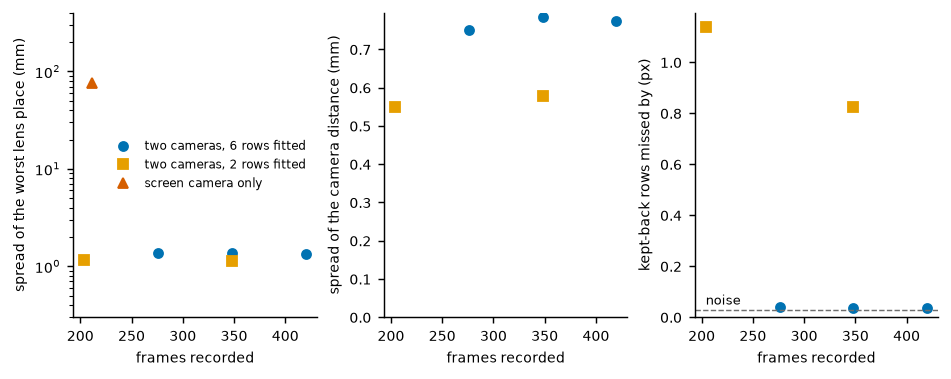

In [10]:
figure, panels = plt.subplots(1, 3, figsize=(7.2, 2.8), constrained_layout=True)
both = [s for s in study if len(s["cameras"]) == 2]
alone = [s for s in study if s["cameras"] == (0,)][0]
order = sorted(both, key=lambda s: s["frames"])
frames = [s["frames"] for s in order]
six = np.array(["6 rows" in s["name"] for s in order])
for panel, values, label in ((panels[0], [s["z"].std(0).max() * 1e3 for s in order], "spread of the worst lens place (mm)"),
                             (panels[1], [s["separation"].std() * 1e3 for s in order], "spread of the camera distance (mm)"),
                             (panels[2], [s["kept"].max() for s in order], "kept-back rows missed by (px)")):
    values = np.array(values)
    panel.plot(np.array(frames)[six], values[six], "o", color=BLUE, ms=5, label="two cameras, 6 rows fitted")
    panel.plot(np.array(frames)[~six], values[~six], "s", color=ORANGE, ms=5, label="two cameras, 2 rows fitted")
    panel.set(xlabel="frames recorded", ylabel=label, ylim=(0, None))
panels[0].plot(alone["frames"], alone["z"].std(0).max() * 1e3, "^", color=RED, ms=6, label="screen camera only")
panels[0].set_yscale("log"), panels[0].set_ylim(0.3, 400)
panels[2].axhline(SCATTER_PX * np.sqrt(2), color=GREY, lw=0.8, ls="--")
panels[2].annotate("noise", (frames[0], SCATTER_PX * np.sqrt(2)), xytext=(0, 3), textcoords="offset points", fontsize=7)
panels[0].legend(frameon=False, fontsize=6.5, loc="center right")
plt.show()

**Figure 2, what the frames buy.** Left: how well the lens places are pinned (spread over repeats of the experiment,
worst lens; log scale). Two cameras pin every lens to about a millimetre however few values each lens gets; the
screen camera alone, with the same settings and both rulers, leaves them loose by a hundred times more. Middle: the
distance between the cameras. Right: how well normal rows that were never fitted are predicted; this depends on how
many normal rows were fitted (blue: 6, orange: 2), not on the values per lens. (Each spread is over only a few
repeats, so it is itself rough; set `SEEDS` higher for smoother numbers.)

## 7. The rulers

The kicks give everything in deflector units. Two things with a known size turn them into metres and radians:

- **gold rings** (camera lengths): the ring angle is the wavelength over the lattice spacing, so the ring radius
  gives B in true metres per radian, and with it the size of a CLA2 unit;
- **a grating image** (magnifications): the pitch is known, so its period on the camera gives A, and with it the
  size of a CLA1 unit.

With both, the distance between the cameras comes out of the fit (section 6). The fixed number of section 3 is why:
it is that distance times the two unit sizes.

Without the grating something else has to set the scale. The obvious candidate, holding the objective's focal length
at its true 1.9 mm, barely does: the objective is 2 mm from the specimen and everything else is hundreds of
millimetres away, so the model can stretch all its lengths and the CLA1 unit together and hardly change what the
cameras see.

In [11]:
print(f"{'rulers':34s} {'between the cameras (m)':>25s} {'one CLA1 unit (pm)':>22s}")
for used in ("gold and grating", "gold, objective held at 1.9 mm"):
    runs = [invert(DESIGNS["2 values per lens, 6 rows"], seed, rulers_used=used) for seed in range(SEEDS)]
    separation, cla1 = np.array([r["separation"] for r in runs]), np.array([r["cla1"] for r in runs]) * 1e12
    print(f"{used:34s} {separation.mean():14.4f} +- {separation.std():.4f} {cla1.mean():12.1f} +- {cla1.std():.1f}")
print(f"{'truth':34s} {SEPARATION:14.4f} {abs(KICK[0, 0]) * 1e12:22.1f}")

rulers                               between the cameras (m)     one CLA1 unit (pm)


gold and grating                           0.4504 +- 0.0008        324.9 +- 0.4


gold, objective held at 1.9 mm             0.1534 +- 0.1409      41692.6 +- 69554.2
truth                                      0.4500                  325.3


## 8. Shift and tilt: which line is the axis, and where the lens centres are

**The kicks never need an axis.** A response is half the difference of two beam positions, so where the beam started
cancels. Everything above is untouched by offsets.

**Offsets show in one place:** where the undeflected beam lands, and how that moves when a lens changes. A lens that
the beam passes off-centre bends the whole beam, by (how far off) / (focal length), so changing the lens moves the
beam. With the lens model known from the kicks, the beam positions are a straight-line problem in the unknowns.

**The axis has to be chosen**, because a camera only knows where the beam is on that camera:

- its *direction* is the direction of the lens axes. A magnetic lens turns the picture about its own axis, which
  makes that direction visible. (A line through the middle of both cameras does not work as the axis: it is tilted
  against the lenses by however far the Merlin sits off, and the fit below then misses by pixels.)
- its *position* is a choice: through the middle pixel of the screen camera.

**Found, measured from that line:** the centre of IL1, IL2, IL3 and PL1, the beam's position and tilt at the
specimen with the deflectors at their console values, and where the Merlin's middle is.

**Not separable:** the objective's own centre, because the objective is never changed here. An off-centre objective
looks exactly like a beam that arrives shifted and tilted, so it is folded into those two numbers.

In the rows the beam is brought back to the middle of the screen camera with CLA1 (MAG) or CLA2 (DIFF), as the
recording script does; the deflector values it took are known and are part of the model. A beam centre is taken as
good to 0.05 px.

In [12]:
CENTRE_SCATTER_PX = 0.05
BEAM = np.array([40e-9, -25e-9, 0.3e-3, -0.2e-3])   # the virtual beam at the specimen: x, y (m), tilt x, y (rad)
design = DESIGNS["2 values per lens, 6 rows"]
result = invert(design, seed=0)
numbers = jax.tree_util.tree_map(jnp.asarray, result["numbers"])
used = [i for i, (stage, name, _) in enumerate(settings)
        if stage in ("weak", "rows") and (stage == "weak" or name in {f"{m} {v}" for m, v in ROWS[:design["rows"]]})
        or stage in LENSES and int(name.split()[1]) in design[stage]]
rng = np.random.default_rng(7)
recentred = np.zeros((len(used), 4))                 # CLA1 x, y and CLA2 x, y added to bring the beam to the middle
for j, i in enumerate(used):
    if settings[i][0] == "rows":
        columns = [2, 3] if settings[i][1].startswith("DIFF") else [0, 1]
        lands = TRUE_MATRICES[i, :2] @ np.r_[BEAM, 1.0]
        recentred[j, columns] = np.round(np.linalg.solve(TRUE_MATRICES[i, :2, :4] @ KICK[:, columns], -lands))
arrives = np.einsum("nij,nj->ni", TRUE_MATRICES[used], np.c_[BEAM + recentred @ KICK.T, np.ones(len(used))])
centres = []                                          # what the cameras would record, px from each camera's middle
for camera, (flight, middle) in enumerate(((0.0, 0j), (SEPARATION, MERLIN_MIDDLE))):
    position = (arrives[:, 0] + flight * arrives[:, 2]) + 1j * (arrives[:, 1] + flight * arrives[:, 3]) - middle
    centres.append(np.exp(1j * ROTATION[camera]) * position / PIXEL[camera]
                   + rng.normal(0, CENTRE_SCATTER_PX, len(used)) + 1j * rng.normal(0, CENTRE_SCATTER_PX, len(used)))
centres = np.array(centres)


def predicted_centres(unknowns, parallel_to_lenses=True):
    "Beam centres (px) on both cameras: lens centres (x, y for IL1..PL1), the beam at the specimen, the Merlin's middle."
    lens_centres, beam, merlin = unknowns[:8].reshape(4, 2), unknowns[8:12], unknowns[12] + 1j * unknowns[13]
    (shift_x, shift_y), (tilt_x, tilt_y) = axes(numbers["CLA1"]), axes(numbers["CLA2"])
    kick = jnp.array([[shift_x.real, shift_y.real, 0, 0], [shift_x.imag, shift_y.imag, 0, 0],
                      [0, 0, tilt_x.real, tilt_y.real], [0, 0, tilt_x.imag, tilt_y.imag]])

    def arrives(dac, extra):
        z = jnp.cumsum(jnp.exp(numbers["lenses"]["log_gaps"]))
        parts = column(numbers["lenses"], dac)
        off_centre = [parts[0]]
        for i, body in enumerate(parts[1:5]):         # each lens acts about its own centre
            off_centre += [Scanner(z=z[i + 1], scan_pos_x=-lens_centres[i, 0], scan_pos_y=-lens_centres[i, 1]), body,
                           Scanner(z=z[i + 1] + body.thickness, scan_pos_x=lens_centres[i, 0], scan_pos_y=lens_centres[i, 1])]
        return column_matrix([*off_centre, parts[5]], voltage=VOLTAGE) @ jnp.concatenate([beam + kick @ extra, jnp.ones(1)])

    ray = jax.vmap(arrives)(jnp.asarray(DACS[used]), jnp.asarray(recentred))
    out = []
    for camera in (0, 1):
        flight = jnp.exp(numbers["log_separation"]) * camera
        turned = jnp.exp(1j * (numbers["camera_rotation"] + camera * numbers["merlin_rotation"])) / PIXEL[camera]
        middle = camera * merlin if parallel_to_lenses else 0.0
        out.append(turned * ((ray[:, 0] + flight * ray[:, 2]) + 1j * (ray[:, 1] + flight * ray[:, 3]) - middle))
    out = jnp.concatenate(out)
    return jnp.concatenate([out.real, out.imag])


recorded = np.concatenate([centres.ravel().real, centres.ravel().imag])
for parallel, label in ((False, "axis through the middle of both cameras"), (True, "axis along the lens axes, through the screen camera's middle")):
    model = lambda unknowns: predicted_centres(unknowns, parallel)
    slopes = np.asarray(jax.jacfwd(model)(jnp.zeros(14)))[:, :14 if parallel else 12]
    found, *_ = np.linalg.lstsq(slopes, recorded - np.asarray(model(jnp.zeros(14))), rcond=None)
    left = slopes @ found - (recorded - np.asarray(model(jnp.zeros(14))))
    print(f"{label}: beam centres fitted to {np.sqrt(np.mean(left ** 2)):.3f} px rms (they are good to {CENTRE_SCATTER_PX} px)")

spread = np.sqrt(np.diag(np.linalg.inv(slopes.T @ slopes))) * CENTRE_SCATTER_PX
lens_found, lens_true = found[:8].reshape(4, 2), np.array([TRUTH["lenses"][n]["offset_m"] for n in LENSES])
print(f"\n{'':32s} {'found':>18s} {'truth':>18s}   good to")
for i, name in enumerate(LENSES):
    print(f"{name + ' centre (um)':32s} {lens_found[i, 0] * 1e6:8.2f} {lens_found[i, 1] * 1e6:8.2f}  {lens_true[i, 0] * 1e6:8.2f} {lens_true[i, 1] * 1e6:8.2f}   {spread[2 * i] * 1e6:.2f}")
for i, name in enumerate(LENSES[1:], 1):
    print(f"{name + ' from IL1 (um)':32s} {(lens_found[i, 0] - lens_found[0, 0]) * 1e6:8.2f} {(lens_found[i, 1] - lens_found[0, 1]) * 1e6:8.2f}  "
          f"{(lens_true[i, 0] - lens_true[0, 0]) * 1e6:8.2f} {(lens_true[i, 1] - lens_true[0, 1]) * 1e6:8.2f}")
print(f"{'beam at the specimen (nm)':32s} {found[8] * 1e9:8.1f} {found[9] * 1e9:8.1f}  {BEAM[0] * 1e9:8.1f} {BEAM[1] * 1e9:8.1f}   {spread[8] * 1e9:.1f}")
print(f"{'beam tilt at the specimen (mrad)':32s} {found[10] * 1e3:8.3f} {found[11] * 1e3:8.3f}  {BEAM[2] * 1e3:8.3f} {BEAM[3] * 1e3:8.3f}   {spread[10] * 1e3:.3f}")
print(f"{'Merlin middle (mm)':32s} {found[12] * 1e3:8.4f} {found[13] * 1e3:8.4f}  {MERLIN_MIDDLE.real * 1e3:8.4f} {MERLIN_MIDDLE.imag * 1e3:8.4f}   {spread[12] * 1e3:.4f}")

axis through the middle of both cameras: beam centres fitted to 2.869 px rms (they are good to 0.05 px)


axis along the lens axes, through the screen camera's middle: beam centres fitted to 0.037 px rms (they are good to 0.05 px)

                                              found              truth   good to
IL1 centre (um)                      3.85    -3.48      1.00    -0.60   1.46
IL2 centre (um)                      2.03    -2.40     -0.80     0.50   1.46
IL3 centre (um)                      3.32    -2.01      0.50     0.90   1.46
PL1 centre (um)                      4.77    -4.45      2.00    -1.50   1.46
IL2 from IL1 (um)                   -1.82     1.09     -1.80     1.10
IL3 from IL1 (um)                   -0.53     1.47     -0.50     1.50
PL1 from IL1 (um)                    0.92    -0.97      1.00    -0.90
beam at the specimen (nm)           -15.3     30.5      40.0    -25.0   28.2
beam tilt at the specimen (mrad)    1.816   -1.690     0.300   -0.200   0.771
Merlin middle (mm)                 0.6036  -0.4023    0.6000  -0.4000   0.0016


The lens centres relative to each other come out far better than each one alone. What is loose is one shared number:
where the whole column sits against the screen camera's middle pixel. A beam centre on that camera is good to
0.05 px, which is 5 um there, and no fit can place the lenses against the camera better than the camera places the
beam. The beam's tilt at the specimen is loose for the same reason: sliding everything by a micrometre is, at the
objective, a tilt of half a milliradian.

## 9. Why not simply many magnifications and camera lengths?

Because the console keeps PL1 at the same strong value (64000) in every row. With PL1 strong, every ray leaves it
through one point just below it, at every magnification and every camera length. The Merlin then shows the screen
camera's picture times one ratio, and the ratio is the same in every row. Below, for all 32 rows of the lens table:
how far the Merlin's responses are from "one ratio times the screen camera's", in pixels for the kick used. It is
under the noise everywhere. So however many rows are recorded, the second camera adds one number, and one camera
over many rows cannot tell where the lenses are (section 6).

With the lenses weak the same difference is pixels: that is the information the ladder uses.

In [13]:
def beyond_one_ratio(dac):
    "The largest difference (px, for the kick used on the Merlin) between the Merlin's responses and ratio x screen camera's."
    r = responses(np.asarray(truth_matrices(jnp.array([dac], float))))[0]
    best = np.argmax(np.abs(r[0]))                      # the best-measured response sets the ratio
    kick = min(LARGEST_KICK.max(), AIM_PX[1] / np.abs(r[1]).max())
    return np.abs(r[1] - r[1, best] / r[0, best] * r[0]).max() * kick


every_row = [beyond_one_ratio(row(mode, label)) for mode in ("MAG", "DIFF") for label in TABLE[mode]]
print(f"PL1 in the {len(every_row)} rows of the lens table: {sorted({TABLE[m][l][3] for m in TABLE for l in TABLE[m]})}")
print(f"all {len(every_row)} normal rows: the Merlin differs from a scaled copy by at most {max(every_row):.3f} px (a displacement repeats to {SCATTER_PX} px)")
print(f"all four lenses weak:              {beyond_one_ratio(weak()):.2f} px")
for name in LENSES:
    print(f"{name} at {SWEEP[name][1]}, the others weak:     {beyond_one_ratio(weak(**{name: SWEEP[name][1]})):.2f} px")

PL1 in the 32 rows of the lens table: [64000]
all 32 normal rows: the Merlin differs from a scaled copy by at most 0.015 px (a displacement repeats to 0.02 px)
all four lenses weak:              3.34 px
IL1 at 22000, the others weak:     2.64 px
IL2 at 22000, the others weak:     1.12 px
IL3 at 22000, the others weak:     0.51 px
PL1 at 24000, the others weak:     0.02 px


## 10. The smallest recording that still works

Section 6 recorded both cameras at every setting (276 frames). Most of that is not needed. What matters is which
camera sees which setting:

- **The Merlin is needed at one setting: all four lenses weak.** That is where the slope after the last lens is
  seen, and it is what sets the lengths. Without it the lens places are loose by anything from centimetres to
  metres.
- **The ladder and the rows can stay on the screen camera.** No camera change while the lenses are being found.
- **Two rows on the Merlin too** (a low magnification and a camera length), so that the model also predicts what the
  Merlin shows at normal rows.
- **Two values per lens are needed.** With one, the fit does not find the answer at all.

Below, the same simulated recording and fit as section 6, with only the kicks each recipe records. "Found the
answer" counts the fits whose misfits end at the noise level. A recipe can pass that and still be useless: in the
fourth line every fit matches its recording, with lens places that are wrong by metres, because nothing in that
recording pins them.

In [14]:
is_setting = lambda names: np.array([NAMES[i] in names for i in KICKS["setting"]])
on = lambda camera: KICKS["camera"] == camera
two_values = dict(two([22000, 42000]), rows=6)
one_value = dict(IL1=(42000,), IL2=(42000,), IL3=(42000,), PL1=(64000,), rows=6)
screen_only = on(0) | is_setting({"all weak"})          # everything on the screen camera, all weak on both
merlin_rows = is_setting({"MAG 8000", "DIFF 0.4"})
RECIPES = {
    "both cameras everywhere (section 6)": (two_values, None),
    "THE RECIPE: all weak on both; ladder and rows on the screen camera; 2 rows on the Merlin too": (two_values, screen_only | merlin_rows),
    "the same without the 2 rows on the Merlin": (two_values, screen_only),
    "the recipe, but all weak on the screen camera only": (two_values, on(0) | merlin_rows),
    "the recipe with one value per lens": (one_value, screen_only | merlin_rows),
}
print(f"{'':98s} {'frames':>6s} {'found the':>10s} {'between':>18s} {'lens places:':>20s} {'kept-back rows':>18s}")
print(f"{'':98s} {'':>6s} {'answer':>10s} {'cameras (mm)':>18s} {'worst error (mm)':>20s} {'missed by (px)':>18s}")
recipe_runs = {}
for name, (design, keep) in RECIPES.items():
    runs = [invert(design, seed, keep=keep) for seed in range(SEEDS)]
    recipe_runs[name] = runs
    good = [r for r in runs if r["chi2_per_dof"] < 2]
    separation = np.array([r["separation"] for r in runs]) * 1e3
    worst = max(np.abs(r["z"] - Z_TRUE)[1:5].max() for r in runs) * 1e3
    kept = np.median([r["kept_miss"] for r in runs], axis=0)
    print(f"{name:98s} {runs[0]['frames']:6d} {f'{len(good)} of {len(runs)}':>10s} {separation.mean():9.1f} +- {separation.std():5.1f} "
          f"{worst:20.1f} {kept[0]:9.3f} {kept[1]:8.3f}")
print(f"\ntruth: {SEPARATION * 1e3:.0f} mm between the cameras; kept-back rows: screen camera, Merlin")

                                                                                                   frames  found the            between         lens places:     kept-back rows
                                                                                                              answer       cameras (mm)     worst error (mm)     missed by (px)


both cameras everywhere (section 6)                                                                   276     4 of 4     450.4 +-   0.8                  1.1     0.036    0.039


THE RECIPE: all weak on both; ladder and rows on the screen camera; 2 rows on the Merlin too          168     4 of 4     450.5 +-   0.7                  2.4     0.038    0.050


the same without the 2 rows on the Merlin                                                             150     4 of 4     450.0 +-   2.0                  3.8     0.037    0.132


the recipe, but all weak on the screen camera only                                                    159     4 of 4     580.6 +- 143.7              26206.7     0.038    0.052


the recipe with one value per lens                                                                    132     1 of 4     280.5 +- 136.1               2522.0   109.980  469.270

truth: 450 mm between the cameras; kept-back rows: screen camera, Merlin


The recipe is 168 frames: 18 at the all-weak setting (both cameras), 72 on the ladder (8 settings on the screen
camera), 54 at the six rows (screen camera), 18 at two rows on the Merlin, and 6 ruler frames.

Smaller recipes can be found that still carry enough information on paper (about 90 frames, by dropping single
kicks), but the fit could not find the answer from any of them: each step of the ladder has to pin its lens by itself.

## 11. What to record

This is what `at_the_microscope/record_two_cameras.py` does.

| Stage | Settings | Camera | Frames |
|---|---|---|---|
| weak | IL1, IL2, IL3, PL1 all at 3000 | both | 18 |
| ladder | each lens at two values (22000 and 42000; PL1 24000 and 64000), the other three at 3000 | screen camera | 72 |
| rows | MAG 8000, 40000, 200000 and DIFF 15, 40, 100 cm | screen camera; MAG 8000 and DIFF 40 on the Merlin too | 72 |
| rulers | gold rings at DIFF 40, 80 cm (screen camera) and 15, 20 cm (Merlin); grating image at MAG 8000, 12000 | | 6 |
| kept (optional) | eight other rows, never fitted: the test | screen camera | 72 |

- **Per setting and camera: 9 frames.** The beam not deflected, then CLA1 and CLA2, each + and - along x and y.
- **Keep the beam on the camera, and keep track of it.** At every setting the beam is found, sized with CL3 and
  brought to the middle with CLA1 or CLA2, whichever moves it more there. Every frame's lens and deflector values go
  in the table. A kick is a difference, so centring does not disturb it; section 8 uses the recorded values.
- **PLA neutral throughout.** It sits between the lenses, so a PLA that changed would look like a lens centre that
  moved. In DIFF the pattern is centred with CLA2.
- **The deflector units do not need to be known.** The size of a CLA1 unit and of a CLA2 unit, and the angles
  between their axes, are numbers of the fit: here they start from wrong guesses (300 pm and 10 urad) and come out
  at the truth (325 pm and 15.6 urad) through the two rulers. Without the rulers everything still fits, in deflector
  units.
- **Every lens comes to its value from below, far enough to forget where it was.** This notebook has no lens
  hysteresis. The virtual NEOARM (through the PyJEM imitation) has, and there an approach from 2000 units below is
  not enough: the same row comes out 0.5 % different depending on the settings before it. From 8000 below it is the
  same every time, which is what the recording script uses.
- **The Merlin is the tight one**: its frame is 14 mm across against 53 mm, so the beam has to be smaller there
  (a low magnification row, not a high one).

**What this study does not cover.** It assumes the lenses follow `ElectromagneticLens` from a DAC value of 3000 to
64000, which the real ones may not (iron saturation at the top, leftover field at the bottom); that a beam can be
measured to the same 0.02 px on the Merlin; and that the beam reaches both cameras with the lenses weak. The first
real recording tests all three.

## 12. Extra: the condenser

Everything above is from the specimen down. The kicks are a shift and a tilt *at the specimen*, so the condenser
(CL1, CL3, the aperture, the corrector, CM and the objective's front field) drops out of the lens fit. This section
looks at what the same recording says about the condenser anyway. Figure 3 is the whole virtual column, from the
source to the Merlin.

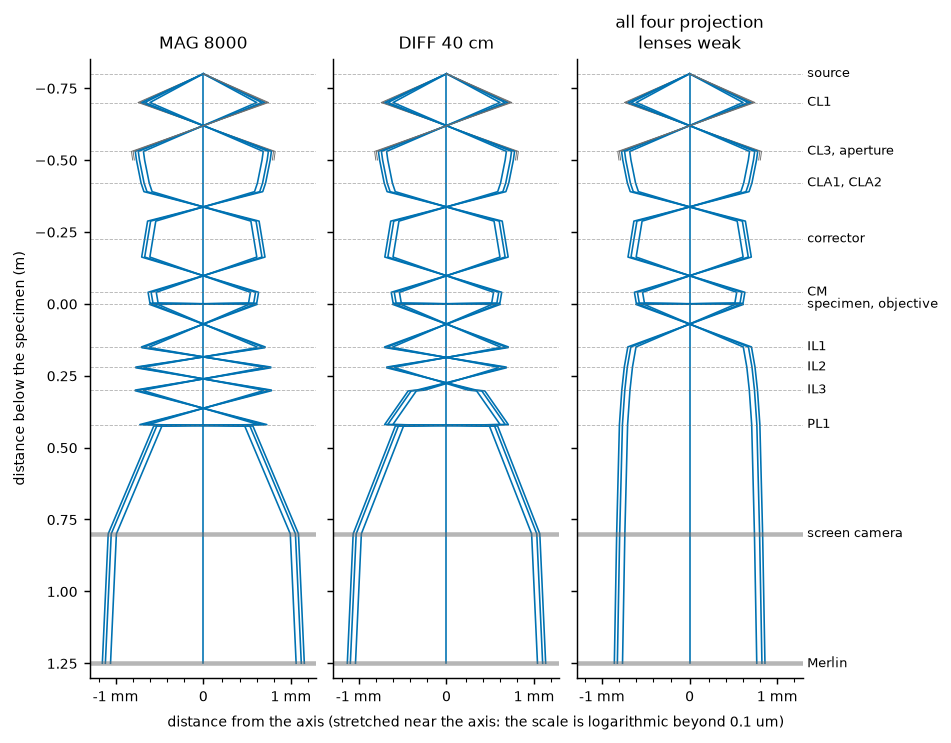

In [15]:
from temgym_core.components import SigmoidAperture
from temgym_core.pyjem_simulator.condenser import Condenser
from temgym_core.run import run_to_end_vmapped
from temgym_core.source import sample_rays

objective = TRUTH["lenses"]["objective"]
condenser = Condenser.from_dict(json.loads(Path("../virtual_neoarm/condenser.json").read_text()),
                                {"z_m": -objective["z_m"], "ampere_turns": objective["ampere_turns"], "Gc": objective["Gc"], "Tc": 0.0})
SPOT = 2


def condenser_parts(cl3_offset=0, hole=1):
    "The virtual condenser from the source to just above the specimen, as TemGym components."
    dac = dict(CL1=condenser.spot_table[SPOT]["CL1"], CL3=condenser.spot_table[SPOT]["CL3"] + cl3_offset, CM=condenser.cm_dac)
    return condenser.components(dac, hole=hole, aperture_position_dac=(2048, 2048), specimen_kick=(0, 0, 0, 0),
                                objective_control=1.0, voltage_v=VOLTAGE)


figure, panels = plt.subplots(1, 3, figsize=(7.2, 5.6), constrained_layout=True, sharey=True)
hole_radius = condenser.hole_diameters_m[0] / 2
for panel, (title, dac) in zip(panels, [("MAG 8000", row("MAG", 8000)), ("DIFF 40 cm", row("DIFF", 0.4)), ("all four projection\nlenses weak", weak())]):
    parts = [*condenser_parts(), *truth_column(jnp.array(dac, float), off_centre=False)[:-1], Plane(z=Z_CAMERA), Plane(z=Z_CAMERA + SEPARATION)]
    angles = jnp.linspace(-1, 1, 11) * 5e-4
    fan = Ray(x=jnp.zeros(11), y=jnp.zeros(11), dx=angles, dy=jnp.zeros(11), z=jnp.full(11, condenser.source_z_m),
              pathlength=jnp.zeros(11), voltage=VOLTAGE)
    z, x = trace_ray_paths(parts, fan, ray_coordinate="x_rot")
    z, x = np.asarray(z), np.asarray(x)
    at_hole = np.flatnonzero(np.isclose(z, condenser.aperture_z_m))[0]
    for ray in range(11):
        through = abs(x[at_hole, ray]) <= hole_radius
        stop = len(z) if through else at_hole + 1
        panel.plot(x[:stop, ray], z[:stop], color=BLUE if through else GREY, lw=0.9 if through else 0.5)
    marks = [(condenser.source_z_m, "source"), (condenser.lenses["CL1"]["z_m"], "CL1"), (condenser.lenses["CL3"]["z_m"], "CL3, aperture"),
             (condenser.deflector_z_m[0], "CLA1, CLA2"), (-0.225, "corrector"), (condenser.lenses["CM"]["z_m"], "CM"),
             (0.0, "specimen, objective"), *[(TRUTH["lenses"][n]["z_m"], n) for n in LENSES], (Z_CAMERA, "screen camera"),
             (Z_CAMERA + SEPARATION, "Merlin")]
    for height, name in marks:
        panel.axhline(height, color=GREY, lw=2.5 if "camera" in name or name == "Merlin" else 0.5, ls="-" if "camera" in name or name == "Merlin" else "--", alpha=0.5)
        if panel is panels[-1]:
            panel.annotate(name, (1.02, height), xycoords=("axes fraction", "data"), va="center", fontsize=7, annotation_clip=False)
    panel.set_xscale("symlog", linthresh=1e-7)
    panel.set(title=title, xlim=(-3e-2, 3e-2), ylim=(1.3, -0.85), xticks=[-1e-3, 0, 1e-3], xticklabels=["-1 mm", "0", "1 mm"])
panels[0].set_ylabel("distance below the specimen (m)")
figure.supxlabel("distance from the axis (stretched near the axis: the scale is logarithmic beyond 0.1 um)", fontsize=8)
plt.show()

**Figure 3, the whole column.** A fan of rays from the middle of the source. Grey rays are stopped by the condenser
aperture (hole 1, 150 um); blue rays go on through the corrector, CM, the specimen and the projection lenses to
both cameras. Left: a magnification row, where the cameras see the beam's size at the specimen. Middle: a camera
length, where they see its spread of angles. Right: the ladder's first rung.

**What the recording gives for the condenser.** The beam it delivers: its size at the specimen from a magnification
row and its spread of angles from a camera length, as in `fit_predictor.ipynb`, but now in nanometres and
milliradians, because the rulers gave the projection lenses their real scale. Each camera gives its own answer, so
they check each other. It costs one frame per camera per condenser setting, and no kicks.

In [16]:
start, mean, covariance = condenser.source()
source_rays = sample_rays(mean, covariance, z=start, voltage=VOLTAGE, sample_power=15)


def beam_at_specimen(cl3_offset):
    "The rays that get through the aperture, at the specimen: x, y (m), tilt x, y (rad)."
    parts = condenser_parts(cl3_offset)
    hole = next(i for i, part in enumerate(parts) if isinstance(part, SigmoidAperture))
    there = run_to_end_vmapped(source_rays, [*parts[:hole], Plane(z=parts[hole].z)])
    through = np.hypot(np.asarray(there.x), np.asarray(there.y)) <= parts[hole].radius
    out = run_to_end_vmapped(source_rays, [*parts, Plane(z=0.0)])
    return np.stack([np.asarray(out.x), np.asarray(out.y), np.asarray(out.dx), np.asarray(out.dy)], axis=1)[through]


rms = lambda x, y: np.sqrt(np.mean((x - x.mean()) ** 2 + (y - y.mean()) ** 2) / 2)
size_row, angle_row = NAMES.index("MAG 8000"), NAMES.index("DIFF 0.15")
per_metre, _ = on_camera(numbers, jnp.array([size_row, size_row]), jnp.array([0, 1]))          # px per m at the specimen
_, per_radian = on_camera(numbers, jnp.array([angle_row, angle_row]), jnp.array([0, 1]))       # px per rad
rng = np.random.default_rng(3)
print(f"{'CL3 from its':>12s}   {'truth':>18s}   {'from the screen camera':>24s}   {'from the Merlin':>24s}")
print(f"{'console value':>12s}   {'nm':>8s} {'mrad':>9s}   {'nm':>8s} {'mrad':>9s} {'(px)':>12s}   {'nm':>8s} {'mrad':>9s} {'(px)':>12s}")
for cl3_offset in (-800, -400, 0, 400, 800, 1500):
    beam = beam_at_specimen(cl3_offset)
    line = f"{cl3_offset:12d}   {rms(beam[:, 0], beam[:, 1]) * 1e9:8.1f} {rms(beam[:, 2], beam[:, 3]) * 1e3:9.3f}"
    for camera, flight in enumerate((0.0, SEPARATION)):
        seen = []
        for setting in (size_row, angle_row):          # the beam's rms radius on this camera, good to 1 %
            lands = (TRUE_MATRICES[setting, :2, :4] + flight * TRUE_MATRICES[setting, 2:4, :4]) @ beam.T
            seen.append(rms(lands[0], lands[1]) / PIXEL[camera] * (1 + rng.normal(0, 0.01)))
        fits = seen[0] < FRAME_PX[camera] / 6
        size = f"{seen[0] / abs(per_metre[camera]) * 1e9:8.1f}" if fits else f"{'too big':>8s}"
        line += f"   {size} {seen[1] / abs(per_radian[camera]) * 1e3:9.3f} {f'({seen[0]:.0f}, {seen[1]:.0f})':>12s}"
    print(line)

CL3 from its                truth     from the screen camera            from the Merlin
console value         nm      mrad         nm      mrad         (px)         nm      mrad         (px)


        -800      122.6     2.875      124.9     2.800       (9, 4)      122.9     2.858     (39, 17)


        -400       24.6     2.817       24.4     2.811       (2, 4)       24.0     2.811      (8, 17)


           0      175.6     2.757      173.8     2.851      (13, 4)    too big     2.748     (56, 16)


         400      330.6     2.695      329.1     2.682      (24, 4)    too big     2.687    (105, 16)


         800      489.5     2.631      491.0     2.631      (36, 4)    too big     2.628    (158, 16)


        1500      777.7     2.514      776.5     2.564      (57, 3)    too big     2.506    (250, 15)


(Where the beam at MAG 8000 would not fit on the Merlin the size is left out; the recording script picks a lower
row for it, as `fit_on_camera` does now.)

**What it does not give: where the condenser lenses are.** The ladder works on the projection lenses because the
kicks send test rays in from above them and the cameras catch both where those rays land and their slope. Nothing
sends a test ray in above the condenser. Three ways to get at it, in order of effort:

1. **The aperture as a ruler** (the idea of three planes: the hole, and the two cameras). The hole has a known
   diameter, so it is a known size at a known plane inside the condenser. `fit_predictor.ipynb` section 10 already
   fits a condenser chain to the beam's size and angle against CL3, spot and hole, but had to hold the CLA1 unit,
   the CLA2 unit and the hole radius at guesses. With the first two now measured, the hole radius is the only thing
   held, and it is a real number. That fit can be redone on this recording with a `shadow` stage of a few CL3
   values and two holes: about 30 frames.
2. **The ladder, mirrored.** Kick the beam above the condenser (the gun deflectors), and read its shift and tilt at
   the specimen with the now-known projection lenses. That would find CL1, CL3 and CM the way IL1 to PL1 are found
   here. The virtual NEOARM does not model the gun deflectors yet.
3. **Nothing more.** For predicting what the microscope does, the beam's size and angle laws are enough.

So: yes for the beam, in real units, at almost no cost; not yet for the condenser's lens places.

`condenser_design.ipynb` takes the first route further: a ladder of condenser settings, fitted with a TemGym
condenser of three lenses, an unknown source and the holes.